# Project 20 — Advanced NLP Readability + External Reliability Validation

**Upgraded notebook: handcrafted features + TF-IDF (unigrams/bigrams and character n-grams) + pretrained sentence embeddings + hybrid models.**

You previously trained a Random Forest on **13 linguistic features**, reaching a moderate test-set R². Now we compare richer text representations **on the same data split** to see whether they *actually* help. The objective remains to predict the human-derived `BT_easiness` score, **not** a 0–100 value.

> Reliability rules: source-work grouping where possible; no fitting vectorizers on validation/test data; choose using validation MAE only; evaluate held-out test data once; reuse the exact preprocessing and fitted vectorizers in Streamlit. Semantic similarity is **not** a validated coherence grade.

**Course connections:** Chapter 2 = NLP pipeline/tokenization; Chapter 3 = BoW, TF-IDF, n-grams and embeddings; Chapter 4 = learning from vector representations and model comparisons.

**New:** sentence-aligned length-aware inference, paired-level external OneStopEnglish tests, without training a separate OneStopEnglish learner-level classifier. The original 5-fold development-only selection remains unchanged.


## 0. Setup (VS Code + uv)

From this folder's terminal (PowerShell):

```powershell
uv python install 3.12
uv python pin 3.12
uv sync
```

Then select `.venv\Scripts\python.exe` as the Jupyter kernel. Do **not** run `%pip install` inside this notebook because `uv` manages the dependencies.

Set `USE_EMBEDDINGS = False` if you want a faster classical-NLP-only run first. The first `True` run downloads a model from Hugging Face; internet is required. On CPU, processing thousands of passages can take substantial time.

In [1]:
import sys
print(sys.executable)

c:\Users\SetupGame\Desktop\nlp_proj_adv\src\nlp_proj_adv\.venv\Scripts\python.exe


In [2]:
from pathlib import Path
from urllib.request import Request, urlopen
import hashlib
import shutil
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
from tqdm.auto import tqdm

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from readability_advanced_utils import (
    FEATURE_NAMES, EMBEDDING_MODEL, extract_features, features_frame, tokenize_words,
    split_sentences, semantic_cohesion, document_embeddings,
    transform_texts, predict_text, suggest_improvements,
    chunk_by_sentences, predict_batch, predict_document,
    EXTERNAL_LEVEL_FEATURES,
)

RANDOM_STATE = 42
USE_EMBEDDINGS = True   # Change to False for a classical NLP comparison without downloading a transformer.
np.random.seed(RANDOM_STATE)
print("Imports successful")

c:\Users\SetupGame\Desktop\nlp_proj_adv\src\nlp_proj_adv\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports successful


## 1. Load CLEAR Corpus

The original workbook has `Excerpt` (text) and `BT_easiness` (human-estimated ease). Higher is easier. The source metadata (`Author`, `Title`) are **not model inputs**; we use them to reduce leakage between training and test passages from the same book/work.

The file is downloaded **only if missing**, written in binary mode, and validated as a ZIP container because `.xlsx` is ZIP-based. An interrupted download will not be mistaken for a complete dataset.

In [3]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "CLEAR_corpus_final.xlsx"
DATA_URL = "https://raw.githubusercontent.com/scrosseye/CLEAR-Corpus/main/CLEAR_corpus_final.xlsx"

if not DATA_PATH.exists():
    print("Downloading the CLEAR Corpus...")
    partial = DATA_PATH.with_suffix(".partial")
    try:
        req = Request(DATA_URL, headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(req, timeout=60) as response, partial.open("wb") as out:
            shutil.copyfileobj(response, out)
        if not zipfile.is_zipfile(partial):
            raise ValueError("The download is not a valid XLSX/ZIP file")
        partial.replace(DATA_PATH)
    except Exception:
        partial.unlink(missing_ok=True)
        raise RuntimeError("Download failed. Download CLEAR_corpus_final.xlsx manually from the official CLEAR-Corpus GitHub repo into data/.")

raw_df = pd.read_excel(DATA_PATH)
print("Original shape:", raw_df.shape)
print("Columns:", raw_df.columns.tolist())
display(raw_df[["Excerpt", "BT_easiness"]].head(3))

Original shape: (4724, 28)
Columns: ['ID', 'Author', 'Title', 'Anthology', 'URL', 'Pub Year', 'Categ', 'Sub Cat', 'Lexile Band', 'Location', 'License', 'MPAA Max', 'MPAA #Max', 'MPAA# Avg', 'Excerpt', 'Google WC', 'Sentence Count', 'Paragraphs', 'BT_easiness', 's.e.', 'Flesch-Reading-Ease', 'Flesch-Kincaid-Grade-Level', 'Automated Readability Index', 'SMOG Readability', 'New Dale-Chall Readability Formula', 'CAREC', 'CAREC_M', 'CML2RI']


,Excerpt,BT_easiness
0,When the young people returned to the ballroom...,-0.340259
1,"All through dinner time, Mrs. Fayre was somewh...",-0.315372
2,"As Roger had predicted, the snow departed as q...",-0.580118


### 1.1 Clean duplicates and targets

We remove missing labels and exact duplicate passages. We **do not** erase punctuation or stopwords from the original text, because these may be informative for readability. The TF-IDF vectorizer can lowercase internally without changing the original passages.

Cleaned passages: 4723


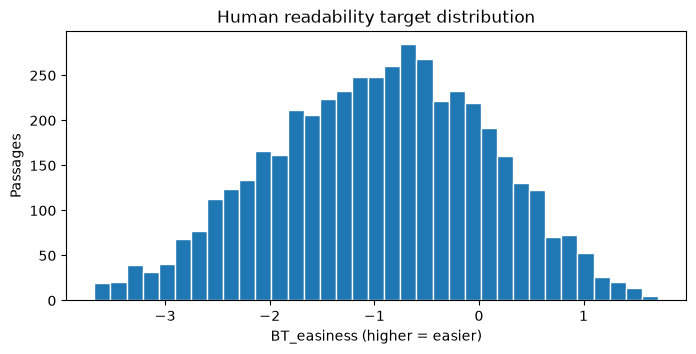

In [4]:
df = raw_df.copy()
df["Excerpt"] = df["Excerpt"].astype("string").str.strip()
df["BT_easiness"] = pd.to_numeric(df["BT_easiness"], errors="coerce")
df = df.dropna(subset=["Excerpt", "BT_easiness"])
df = df[df["Excerpt"].str.len() > 0]
# Avoid same excerpt with different line breaks / capitalization appearing in multiple splits.
df["_normalized_excerpt"] = df["Excerpt"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
df = df.drop_duplicates(subset=["_normalized_excerpt"]).drop(columns=["_normalized_excerpt"]).reset_index(drop=True)   #because if an identical text appears in both training and testing, the model may already have encountered that text during training. thats why we rmove dduplicates because 2 rows that have the same excerpt will have the same features values which can lead to data leakage cuz the model can train on the row and still tests on different row that has same excerpt as the row that the model trained on, thats why we removed duplicates.

y = df["BT_easiness"].to_numpy(dtype=float)
texts = df["Excerpt"].astype(str).tolist() # texts is a list that each value is an entire excerpt of a row.
print("Cleaned passages:", len(df))
assert len(df) >= 1000, "The assignment asks for at least 1,000 passages"

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(y, bins=35, edgecolor="white")
ax.set(title="Human readability target distribution", xlabel="BT_easiness (higher = easier)", ylabel="Passages")
plt.show()

## 2. Reliable train / validation / test split (grouped by source work)

Instead of randomly placing passages from the **same work** into different splits, we group by `Author + Title` where available. If the title is missing, that passage receives a separate fallback group. This is stricter for generalization than a random passage-level split, although it cannot guarantee elimination of all near-duplicates or shared authorship effects.

Approximately 70% train, 15% validation, 15% test. **Do not look at test performance while choosing models.**

In [5]:
def source_groups(data): 
    authors = data["Author"] if "Author" in data else pd.Series([""] * len(data))
    titles = data["Title"] if "Title" in data else pd.Series([""] * len(data))
    groups = []
    for i, (a, t) in enumerate(zip(authors, titles)):
        author = "" if pd.isna(a) else str(a).strip().lower()
        title = "" if pd.isna(t) else str(t).strip().lower()
        groups.append(f"work::{author}::{title}" if title else f"unknown-work::{i}")  # This assigns a group identifier to each excerpt.
    return np.array(groups)

#the function source_groups create identifiers to the groups of passages that have the same title and author and that will prevent 
#excerpts of same book's author or title to exist in different splits. if we used train test split it could make in train set and test set passages from same book's author 
#and title which isn't a problem because the model doesn't receive the book's title or author but passages from same books with the same author and title can have similar 
#sentence structures and used vocabulary etc... so if the model encounters a book with the same author and title in test set it is still considered a generalization because 
#the model dont receive the book's title or author but the model will observe that the passage in the test set have similar sentence structure vocabulary etc... 
#as the passages trained on in training set that have the same author and books title so thats a generalization which is good but when we use groupeshufflesplit with the identifiers returned
#by group_source then the splits will never have passages from the same book's title and author of train set in test set and that means the model will be testing 
#on passages of books he has never seen which will allow us to evaluate its ability to generalize better than the train test split.

groups = source_groups(df)
indices = np.arange(len(df))  # indices: Contains the positions of all 4,723 excerpts: [0, 1, 2, ..., 4722].
outer = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
idx_dev, idx_test = next(outer.split(indices, y, groups))  #idx_dev, idx_test = next(outer.split(indices, y, groups))  
# this says i want indices[0] to be in same set as indices[1] if groups[0] equals groups[1] and  i want indices[7] to be in same set as indices[9] if groups[7] == groups[9] etc...
# GroupShuffleSplit.split() always returns the indices in this order: (training_indices, testing_indices)
# Both arrays contain row indices of passages, but:
# - training_indices contains the indices of passages assigned to the training/development set.
# - testing_indices contains the indices of passages assigned to the test set.
# The important rule is that all passages with the same author AND book title must stay in one set(training or testing), never both.
inner = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE)
relative_train, relative_val = next(inner.split(idx_dev, y[idx_dev], groups[idx_dev]))
# does the same thing as before ( in the outer ) the only difference is now it performs splitting on developpement set only.
# developpement set will be divided to 70% training set and 15% validation set.
idx_train, idx_val = idx_dev[relative_train], idx_dev[relative_val]

# IMPORTANT relative_train contains positions inside idx_dev - idx_dev contains row indices in the original DataFrame - idx_train contains the original row indices selected for training.

#Why do we do this line that is just before this comment?

#Because relative_train and relative_val contain positions inside idx_dev, while we need positions in the original DataFrame. (idx_dev contains row indices from the original DataFrame.)

#This operation converts those relative positions into original row indices.

# verify that no book appears in more than one dataset (Train, Validation, Test).
#assert Raises an AssertionError if the condition is false. btw an empty set() means false so not (set()) is true so it passes
assert not (set(groups[idx_train]) & set(groups[idx_val]))
assert not (set(groups[idx_train]) & set(groups[idx_test]))
assert not (set(groups[idx_val]) & set(groups[idx_test]))

print("Train/val/test:", len(idx_train), len(idx_val), len(idx_test))
print("Unique source groups:", len(set(groups)))
for name, idx in [("Train", idx_train), ("Val", idx_val), ("Test", idx_test)]:
    print(f"{name}: avg target = {y[idx].mean():+.3f}, std = {y[idx].std():.3f}")

Train/val/test: 3309 702 712
Unique source groups: 4678
Train: avg target = -0.939, std = 1.030
Val: avg target = -0.998, std = 1.030
Test: avg target = -1.003, std = 1.051


## 3. Handcrafted linguistic features (the original baseline)

We **keep** your 13 engineered features. These measure sentence/word length, variation, syllables, lexical diversity, lexical overlap, and Flesch formulas. They are interpretable, inexpensive, and usable on brand-new text.

The important point: `features_frame()` computes exactly the same features in training and Streamlit. The rule-based features are not fitted on the dataset, so extracting them for all texts before splitting is fine. The scaler **will be fitted only on training data**.

In [6]:
X_manual = features_frame(tqdm(texts, desc="Extracting linguistic features"))
assert X_manual.columns.tolist() == FEATURE_NAMES
assert np.isfinite(X_manual.to_numpy()).all(), "Invalid linguistic feature values"
display(X_manual.head(3))

example = "Teachers explain the lesson. Students understand the example."
print("Example input:", example)
display(pd.Series(extract_features(example), name="value").to_frame())
print("Sentences:", split_sentences(example))

Extracting linguistic features: 100%|██████████| 4723/4723 [00:04<00:00, 961.03it/s] 


,word_count,sentence_count,avg_sentence_length,sentence_length_std,avg_word_length,long_word_ratio,polysyllabic_ratio,syllables_per_word,lexical_diversity,connector_ratio,lexical_cohesion,flesch_reading_ease,flesch_kincaid_grade
0,181.0,11.0,16.454545,6.372721,4.348066,0.165746,0.060773,1.298343,0.580110,0.005525,0.026950,79.251143,6.247984
1,169.0,12.0,14.083333,10.201784,4.236686,0.153846,0.059172,1.366864,0.650888,0.005917,0.000000,78.945814,5.246851
2,168.0,9.0,18.666667,12.055428,4.166667,0.154762,0.071429,1.339286,0.702381,0.011905,0.017677,78.125492,5.798976


Example input: Teachers explain the lesson. Students understand the example.


,value
word_count,8.000
sentence_count,2.000
avg_sentence_length,4.000
sentence_length_std,0.000
avg_word_length,6.500
long_word_ratio,0.625
polysyllabic_ratio,0.250
syllables_per_word,2.000
lexical_diversity,0.875
connector_ratio,0.000


Sentences: ['Teachers explain the lesson.', 'Students understand the example.']


In [7]:
# Statistics for the data used to train the final model
train_features = X_manual.iloc[idx_dev]

cols = [
    "word_count",
    "sentence_count",
    "avg_sentence_length"
]

print("CLEAR Corpus — Training data statistics")

display(
    train_features[cols].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    ).round(2)
)

CLEAR Corpus — Training data statistics


,word_count,sentence_count,avg_sentence_length
count,4011.00,4011.00,4011.00
mean,174.15,9.18,22.41
std,17.17,4.16,10.30
min,113.00,1.00,4.62
25%,161.00,7.00,16.25
50%,176.00,8.00,20.89
75%,189.00,11.00,26.43
90%,196.00,14.00,32.40
95%,199.00,17.00,38.80
max,215.00,39.00,161.00


## 4. TF-IDF vectorization and n-grams

**Chapter 3 concepts:**

- Word TF-IDF (`ngram_range=(1, 2)`) measures the importance of individual words and word pairs.
- Character TF-IDF (`analyzer="char_wb"`, 3–5) represents short character sequences. This helps capture morphological patterns and words outside the learned word vocabulary.
- Both yield **sparse vectors**, not semantic embeddings. Similar meanings with different words can remain far apart.

**Leakage rule:** `fit` is performed on training passages **only**. Validation is only transformed using the previously learned vocabulary/IDF weights.

In [ ]:
def new_word_vectorizer():
    return TfidfVectorizer(
        lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.98,
        max_features=30000, sublinear_tf=True, dtype=np.float32,
    )

def new_char_vectorizer():
    return TfidfVectorizer(  
        analyzer="char_wb", ngram_range=(3, 5), min_df=2,
        max_features=30000, sublinear_tf=True, dtype=np.float32,
    )
#-analyzer = "char_wb" tells the vectorizer to process each word separately when extracting groups of characters 
#-maxfeatures tells the vectorizer to keep only 30000 of the grams.
# example suppose If the vectorizer made 100,000 different n-grams across the training passages, max_features=30000 limits the vocabulary to at most 30,000 n-grams.
#-ngramrange means in each group of characters there are 3 or 4 or 5 characters
#-when processing words the vectorizer does add spaces in beginning and ending of the words to help recognize the ending and beginning of the word.
#-mindf = 2 means keep the words or grams that apppears at least in 2 different training passages. example : Suppose the character n-gram "ing" 
# appears in: Passage 1: "learning" - Passage 2: "working" - Passage 3: "playing" so Its document frequency is 3, because it appears in three different passages.
# Since min_df=2, the n-gram "ing" passes the minimum-frequency filter.
#-maxdf = 0.98 Remove words or n-grams appearing in more than 98% of training passages.
#-sublinear_tf=True reduces the influence of words or n-grams that appear too many times in the same passage. cuz as we know the tf is term frequency so imagine if a gram appears 50 times
# in a passage so Without sublinear scaling, its high repetition could give it excessive influence.
# With sublinear_tf=True, repetition still increases its TF-IDF contribution, but much more slowly.
# This helps the model focus less on excessive repetition and more on a passage's overall vocabulary patterns.
word_vec = new_word_vectorizer()
char_vec = new_char_vectorizer()
scaler = StandardScaler()

train_texts = [texts[i] for i in idx_train]
val_texts = [texts[i] for i in idx_val]

word_vec.fit(train_texts)   # examines all training passages Builds the vocabulary of retained n-grams, 
# Counts how many passages contain each n-gram , Calculates the IDF weight for each retained n-gram.
# later in the word_vec.transform(train_texts) will calculate the TF of each ngram, applies sublinear TF scaling (1 + ln(TF)),
# and multiply TF by the IDF weights learned during fit(train_texts) to generate the numerical TF-IDF features, 
# These numerical features will later be combined with other features and passed to our Ridge regression model.
char_vec.fit(train_texts) 
# same thing as word_vec will happen to char_vec
scaler.fit(X_manual.iloc[idx_train])  
#This calculates learns the mean and standard deviation of each of the 13 linguistic feature columns, using only the training rows.

print("Word TF-IDF features:", len(word_vec.vocabulary_))
print("Character TF-IDF features:", len(char_vec.vocabulary_))
print("Example words:", word_vec.get_feature_names_out()[:15].tolist())

Word TF-IDF features: 30000
Character TF-IDF features: 30000
Example words: ['00', '000', '000 000', '000 and', '000 in', '000 it', '000 men', '000 metres', '000 miles', '000 of', '000 people', '000 to', '000 years', '10', '10 000']


In [9]:
x_mjrb = X_manual.iloc[idx_train]
x_mjrb.head()

,word_count,sentence_count,avg_sentence_length,sentence_length_std,avg_word_length,long_word_ratio,polysyllabic_ratio,syllables_per_word,lexical_diversity,connector_ratio,lexical_cohesion,flesch_reading_ease,flesch_kincaid_grade
0,181.0,11.0,16.454545,6.372721,4.348066,0.165746,0.060773,1.298343,0.580110,0.005525,0.026950,79.251143,6.247984
1,169.0,12.0,14.083333,10.201784,4.236686,0.153846,0.059172,1.366864,0.650888,0.005917,0.000000,78.945814,5.246851
3,163.0,4.0,40.750000,35.074029,4.049080,0.116564,0.036810,1.233129,0.631902,0.012270,0.048336,46.092830,19.996981
4,167.0,5.0,33.400000,15.291828,4.269461,0.131737,0.011976,1.197605,0.670659,0.000000,0.014297,70.372268,11.592244
6,163.0,7.0,23.285714,12.769543,4.496933,0.233129,0.122699,1.515337,0.644172,0.006135,0.040722,55.002454,11.372410


## 5. Pretrained sentence embeddings (optional, recommended experiment)

An embedding maps a passage into a learned dense vector. We use the pretrained **all-MiniLM-L6-v2** sentence-transformer (384 dimensions), not a model trained on CLEAR labels.

**Important:** This model is intended primarily for semantic similarity, not specifically readability. It may improve predictions, or it may not. Its input length is limited, so we split long passages into ~90-word chunks, encode them, average the chunk embeddings, then normalize. This avoids dropping the end of a long excerpt.

To speed up reruns, vectors are cached with a dataset-and-model hash. Switch `USE_EMBEDDINGS=False` for low-resource computers.

In [10]:
encoder = None # Will contain the pretrained SentenceTransformer model.
X_emb = None # Will contain the numerical embeddings of our passages.
if USE_EMBEDDINGS:
    try:
        from sentence_transformers import SentenceTransformer
        encoder = SentenceTransformer(EMBEDDING_MODEL) # SentenceTransformer loads our pretrained MiniLM model. This model converts text into 384 numerical values representing semantic information.
        fingerprint = hashlib.sha256(
            (EMBEDDING_MODEL + "|chunk90|" + "||".join(texts)).encode("utf-8")
        ).hexdigest()[:16]
        cache_file = DATA_DIR / f"doc_embeddings_{fingerprint}.npz"
        if cache_file.exists():
            print("Loading cached document embeddings:", cache_file)
            X_emb = np.load(cache_file)["embeddings"]
        else:
            print("Encoding passages with", EMBEDDING_MODEL)
            X_emb = document_embeddings(texts, encoder, batch_size=32) #MiniLM performs inference:Receives passages as input.
            #Processes them using its already-learned parameters.
            # Produces a 384-dimensional embedding for each passage.
            #X_emb Contains embeddings for all 4,723 passages.
            #X_emb[0] Contains the 384 numerical values representing the first passage.
            np.savez_compressed(cache_file, embeddings=X_emb) #Saves the results into a compressed NumPy file
        assert X_emb.shape[0] == len(texts)
        print("Embeddings shape:", X_emb.shape)
    except Exception as exc:
        print("Embedding experiment unavailable:", repr(exc))
        print("Classical TF-IDF and linguistic models will still run.")
        X_emb = None
        encoder = None
else:
    print("Embedding experiment skipped by configuration.")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5875.89it/s]


Loading cached document embeddings: data\doc_embeddings_c3ea5b0519cd0e7a.npz
Embeddings shape: (4723, 384)


## 6. Build comparable candidate representations

Models evaluated on the **same validation passages**:

1. **Linguistic (RF)** — the original Random Forest baseline.
2. **TF-IDF words (Ridge)** — word unigrams and bigrams.
3. **TF-IDF + linguistic (Ridge)** — word TF-IDF + character TF-IDF + scaled 13 features.
4. **Embeddings + linguistic (Ridge)** — dense pretrained semantics + scaled linguistic features.
5. **Hybrid all (Ridge)** — word/character TF-IDF + linguistic features + pretrained embeddings.

Using a regularized linear **Ridge regressor** is a practical fit for high-dimensional TF-IDF features. The Random Forest is reserved for low-dimensional linguistic features.

In [ ]:
representation_names = [
    "Linguistic (Ridge)",
    "TF-IDF words (Ridge)",
    "TF-IDF + linguistic (Ridge)",
]

if X_emb is not None:
    representation_names += [
        "Embeddings + linguistic (Ridge)",
        "Hybrid all (Ridge)"
    ]

X_train_by_rep, X_val_by_rep = {}, {}
for name in representation_names:
    X_train_by_rep[name] = transform_texts(
        train_texts, name, word_vec, char_vec, scaler,
        precomputed_features=X_manual.iloc[idx_train],
        precomputed_embeddings=X_emb[idx_train] if X_emb is not None else None,
    )
    X_val_by_rep[name] = transform_texts(
        val_texts, name, word_vec, char_vec, scaler,
        precomputed_features=X_manual.iloc[idx_val],
        precomputed_embeddings=X_emb[idx_val] if X_emb is not None else None,
    )
    print(name, '→', X_train_by_rep[name].shape)

Linguistic (Ridge) → (3309, 13)
TF-IDF words (Ridge) → (3309, 30000)
TF-IDF + linguistic (Ridge) → (3309, 60013)
Embeddings + linguistic (Ridge) → (3309, 397)
Hybrid all (Ridge) → (3309, 60397)


## 7. Five-fold group cross-validation — compare representations before choosing the model

We compare all candidate models on development-only groups. Each fold fits a fresh TF-IDF vocabulary and scaler using its own training data. Choose by mean validation MAE; never use final CLEAR test data for selection.

In [12]:

from sklearn.model_selection import GroupKFold

# Evaluation metrics
def metrics(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions)
    }


# 5-fold cross-validation on DEVELOPMENT data only
cv = GroupKFold(n_splits=5)

cv_results = []

for fold, (train_local, val_local) in enumerate(
    cv.split(
        X_manual.iloc[idx_dev],
        y[idx_dev],
        groups=groups[idx_dev]
    ),
    start=1
):
    print(f"\n========== Fold {fold}/5 ==========")

    # Convert local fold indices to original dataset indices
    train_idx = idx_dev[train_local]
    val_idx = idx_dev[val_local]

    # Verify source groups do not overlap
    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(train_idx).isdisjoint(set(idx_test))
    assert set(val_idx).isdisjoint(set(idx_test))

    fold_train_texts = [texts[i] for i in train_idx]
    fold_val_texts = [texts[i] for i in val_idx]

    # Create new vectorizers and scaler for every fold
    wv = new_word_vectorizer()
    cv_char = new_char_vectorizer()
    sc = StandardScaler()

    # Fit using only this fold's training data
    wv.fit(fold_train_texts)
    cv_char.fit(fold_train_texts)
    sc.fit(X_manual.iloc[train_idx])

    # Test all available representations
    for name in representation_names:

        # Prepare training features
        X_tr = transform_texts(
            fold_train_texts,
            name,
            wv,
            cv_char,
            sc,
            precomputed_features=X_manual.iloc[train_idx],
            precomputed_embeddings=(
                X_emb[train_idx] if X_emb is not None else None
            )
        )

        # Prepare validation features
        X_va = transform_texts(
            fold_val_texts,
            name,
            wv,
            cv_char,
            sc,
            precomputed_features=X_manual.iloc[val_idx],
            precomputed_embeddings=(
                X_emb[val_idx] if X_emb is not None else None
            )
        )

        # Random Forest has no alpha parameter
        if name == "Linguistic (RF)":
            alphas = [None]
        else:
            alphas = [1.0, 10.0, 100.0]

        for alpha in [1.0, 10.0, 100.0]:

            model = Ridge(
                alpha=alpha,
                solver="lsqr"
            )

            model.fit(X_tr, y[train_idx])

            predictions = model.predict(X_va)

            cv_results.append({
                "Fold": fold,
                "Representation": name,
                "alpha": alpha,
                **metrics(y[val_idx], predictions)
            })

    print(f"Fold {fold} completed.")


# Detailed results for every model and fold
cv_df = pd.DataFrame(cv_results)

# Mean and standard deviation across 5 folds
cv_summary = (
    cv_df
    .groupby(["Representation", "alpha"], dropna=False)
    .agg(
        MAE=("MAE", "mean"),
        MAE_std=("MAE", "std"),
        RMSE=("RMSE", "mean"),
        RMSE_std=("RMSE", "std"),
        R2=("R2", "mean"),
        R2_std=("R2", "std")
    )
    .reset_index()
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\nCross-validation results:")
display(cv_summary.round(4))

# Keep names compatible with the following notebook cells
validation_table = cv_summary[
    ["Representation", "alpha", "MAE", "RMSE", "R2"]
].copy()

# Select best model by lowest average MAE
selected = cv_summary.iloc[0]

best_representation = selected["Representation"]

best_alpha = (
    None if pd.isna(selected["alpha"])
    else float(selected["alpha"])
)

print("\nSELECTED MODEL:", best_representation)
print("SELECTED ALPHA:", best_alpha)
print("CV mean MAE:", round(float(selected["MAE"]), 4))
print("CV std MAE:", round(float(selected["MAE_std"]), 4))
print("CV mean R2:", round(float(selected["R2"]), 4))
print("CV std R2:", round(float(selected["R2_std"]), 4))



========== Fold 1/5 ==========
Fold 1 completed.

========== Fold 2/5 ==========
Fold 2 completed.

========== Fold 3/5 ==========
Fold 3 completed.

========== Fold 4/5 ==========
Fold 4 completed.

========== Fold 5/5 ==========
Fold 5 completed.

Cross-validation results:


,Representation,alpha,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std
0,Hybrid all (Ridge),1.0,0.4881,0.0152,0.6178,0.0150,0.6384,0.0308
1,Hybrid all (Ridge),10.0,0.4986,0.0133,0.6280,0.0162,0.6264,0.0314
2,Embeddings + linguistic (Ridge),1.0,0.5005,0.0129,0.6315,0.0166,0.6220,0.0357
3,Embeddings + linguistic (Ridge),10.0,0.5183,0.0132,0.6523,0.0166,0.5968,0.0350
4,TF-IDF + linguistic (Ridge),1.0,0.5389,0.0171,0.6756,0.0227,0.5679,0.0326
5,TF-IDF + linguistic (Ridge),10.0,0.5656,0.0181,0.7122,0.0220,0.5200,0.0338
6,TF-IDF words (Ridge),1.0,0.5686,0.0190,0.7133,0.0214,0.5189,0.0247
7,Hybrid all (Ridge),100.0,0.5885,0.0184,0.7400,0.0206,0.4817,0.0365
8,Embeddings + linguistic (Ridge),100.0,0.6017,0.0186,0.7564,0.0206,0.4585,0.0378
9,TF-IDF + linguistic (Ridge),100.0,0.6385,0.0213,0.8024,0.0233,0.3907,0.0404



SELECTED MODEL: Hybrid all (Ridge)
SELECTED ALPHA: 1.0
CV mean MAE: 0.4881
CV std MAE: 0.0152
CV mean R2: 0.6384
CV std R2: 0.0308


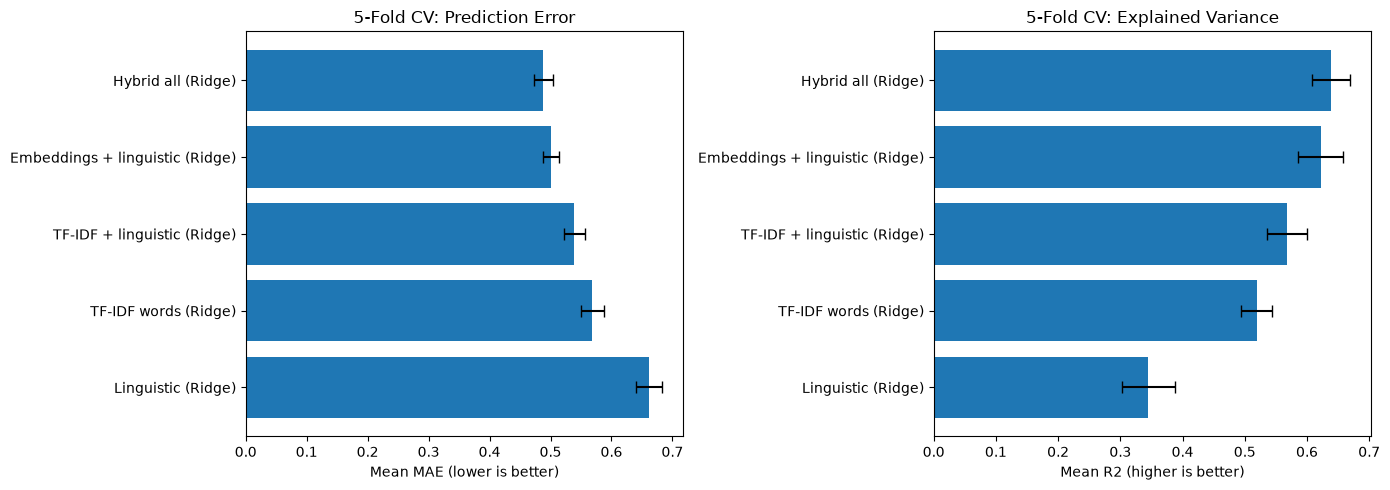

In [13]:

# Keep only the best alpha for each representation
best_per_model = (
    cv_summary
    .sort_values("MAE")
    .drop_duplicates(subset="Representation")
    .sort_values("MAE")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average MAE with standard deviation
axes[0].barh(
    best_per_model["Representation"],
    best_per_model["MAE"],
    xerr=best_per_model["MAE_std"],
    capsize=4
)
axes[0].invert_yaxis()
axes[0].set_xlabel("Mean MAE (lower is better)")
axes[0].set_title("5-Fold CV: Prediction Error")

# Average R2 with standard deviation
axes[1].barh(
    best_per_model["Representation"],
    best_per_model["R2"],
    xerr=best_per_model["R2_std"],
    capsize=4
)
axes[1].invert_yaxis()
axes[1].set_xlabel("Mean R2 (higher is better)")
axes[1].set_title("5-Fold CV: Explained Variance")

plt.tight_layout()
plt.show()


## 8. Refit the selected approach on TRAIN + VALIDATION

Once we have selected the approach, it is acceptable to refit vectorizers, scalers, and the final estimator on the **full development set**. This means: train+validation only. The held-out test set remains untouched until the next section.

We save the vectorizers, scaler, selected estimator, feature names, and readability cutoffs in **one joblib artifact**. This is crucial: Streamlit must use the *same fitted vocabulary and feature order* as training.

In [14]:
dev_texts = [texts[i] for i in idx_dev]
test_texts = [texts[i] for i in idx_test]

final_word_vec = new_word_vectorizer()
final_char_vec = new_char_vectorizer()
final_scaler = StandardScaler()
final_word_vec.fit(dev_texts)
final_char_vec.fit(dev_texts)
final_scaler.fit(X_manual.iloc[idx_dev])

X_dev_final = transform_texts(
    dev_texts, best_representation, final_word_vec, final_char_vec, final_scaler,
    precomputed_features=X_manual.iloc[idx_dev],
    precomputed_embeddings=X_emb[idx_dev] if X_emb is not None else None,
)
X_test_final = transform_texts(
    test_texts, best_representation, final_word_vec, final_char_vec, final_scaler,
    precomputed_features=X_manual.iloc[idx_test],
    precomputed_embeddings=X_emb[idx_test] if X_emb is not None else None,
)

final_model = Ridge(
    alpha=best_alpha,
    solver="lsqr"
)

final_model.fit(X_dev_final, y[idx_dev])

final_model.fit(X_dev_final, y[idx_dev])
print("Final model fit on", len(idx_dev), "development passages")

Final model fit on 4011 development passages


## 9. Evaluate ONCE on held-out test passages

The mean baseline predicts the *development-set mean BT_easiness* for every test text. The selected model must beat it to show that features add predictive value. Ideally, compare your new test results with your original Random Forest result, while remembering the new group-aware split is stricter and **not directly identical** to your old split.

,Model,MAE,RMSE,R2
0,Mean baseline,0.8652,1.0527,-0.0026
1,Hybrid all (Ridge),0.5108,0.6405,0.6289


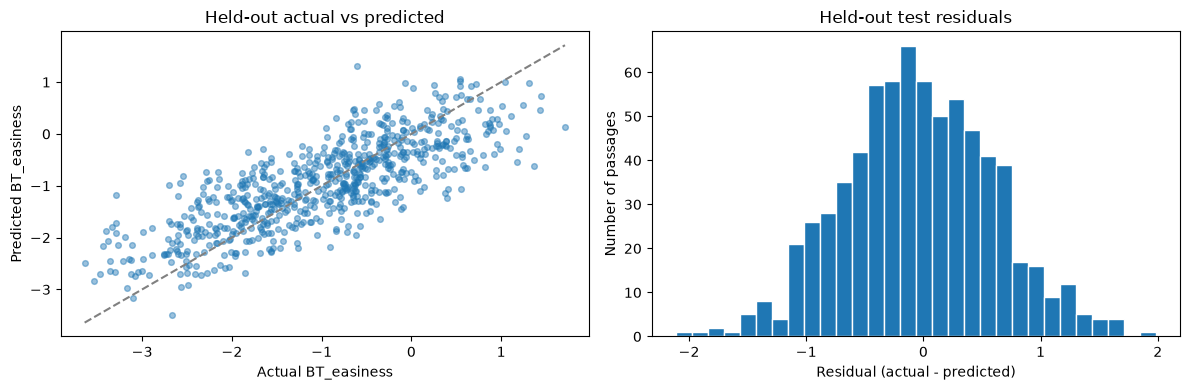

In [15]:
test_pred = final_model.predict(X_test_final)
mean_pred = np.full(len(idx_test), float(y[idx_dev].mean()))
test_table = pd.DataFrame([
    {"Model": "Mean baseline", **metrics(y[idx_test], mean_pred)},
    {"Model": best_representation, **metrics(y[idx_test], test_pred)},
])
display(test_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y[idx_test], test_pred, alpha=0.45, s=17)
low = min(float(y[idx_test].min()), float(test_pred.min()))
high = max(float(y[idx_test].max()), float(test_pred.max()))
axes[0].plot([low, high], [low, high], linestyle="--", color="gray")
axes[0].set(xlabel="Actual BT_easiness", ylabel="Predicted BT_easiness", title="Held-out actual vs predicted")
axes[1].hist(y[idx_test] - test_pred, bins=30, edgecolor="white")
axes[1].set(xlabel="Residual (actual - predicted)", ylabel="Number of passages", title="Held-out test residuals")
plt.tight_layout(); plt.show()

In [16]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Determine length boundaries from CLEAR development data
q1, q2 = X_manual.iloc[idx_dev]["word_count"].quantile([1/3, 2/3])

print(f"Short: <= {q1:.0f} words")
print(f"Medium: {q1:.0f} to {q2:.0f} words")
print(f"Long: > {q2:.0f} words")

# Create a DataFrame containing test predictions
length_results = pd.DataFrame({
    "word_count": X_manual.iloc[idx_test]["word_count"].to_numpy(),
    "Actual": y[idx_test],
    "Predicted": test_pred
})

# Calculate absolute error
length_results["Absolute Error"] = abs(
    length_results["Actual"] - length_results["Predicted"]
)

# Divide texts into groups
length_results["Length"] = pd.cut(
    length_results["word_count"],
    bins=[-np.inf, q1, q2, np.inf],
    labels=["Short", "Medium", "Long"]
)

# Calculate MAE for each group
summary = length_results.groupby(
    "Length", observed=True
).agg(
    Number_of_texts=("Absolute Error", "count"),
    Average_words=("word_count", "mean"),
    Min_words=("word_count", "min"),
    Max_words=("word_count", "max"),
    MAE=("Absolute Error", "mean")
)

display(summary.round(3))

Short: <= 166 words
Medium: 166 to 184 words
Long: > 184 words


,Number_of_texts,Average_words,Min_words,Max_words,MAE
Length,,,,,
Short,250,154.396,136.0,166.0,0.486
Medium,225,175.844,167.0,184.0,0.512
Long,237,192.810,185.0,205.0,0.535


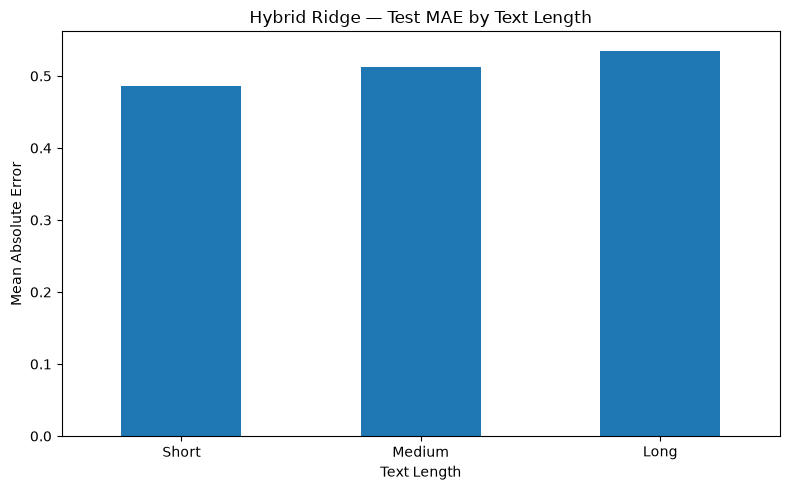

In [17]:
import matplotlib.pyplot as plt

summary["MAE"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Hybrid Ridge — Test MAE by Text Length")
plt.xlabel("Text Length")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 9.2 Feature Importance Analysis — Permutation Importance

This section evaluates which linguistic features contribute most to the predictions of the final Hybrid Ridge model.

We use permutation importance: each feature is randomly shuffled while keeping the others unchanged. We then measure how much the prediction error (MAE) increases.

A larger increase in MAE suggests that the model relies more strongly on that feature.

Original Test MAE: 0.5108


,Feature,MAE Increase,Std
7,syllables_per_word,0.0614,0.0064
12,flesch_kincaid_grade,0.0400,0.0054
11,flesch_reading_ease,0.0218,0.0084
0,word_count,0.0096,0.0046
3,sentence_length_std,0.0045,0.0010
5,long_word_ratio,0.0010,0.0007
4,avg_word_length,0.0006,0.0001
10,lexical_cohesion,0.0001,0.0003
8,lexical_diversity,0.0000,0.0009
9,connector_ratio,-0.0000,0.0000


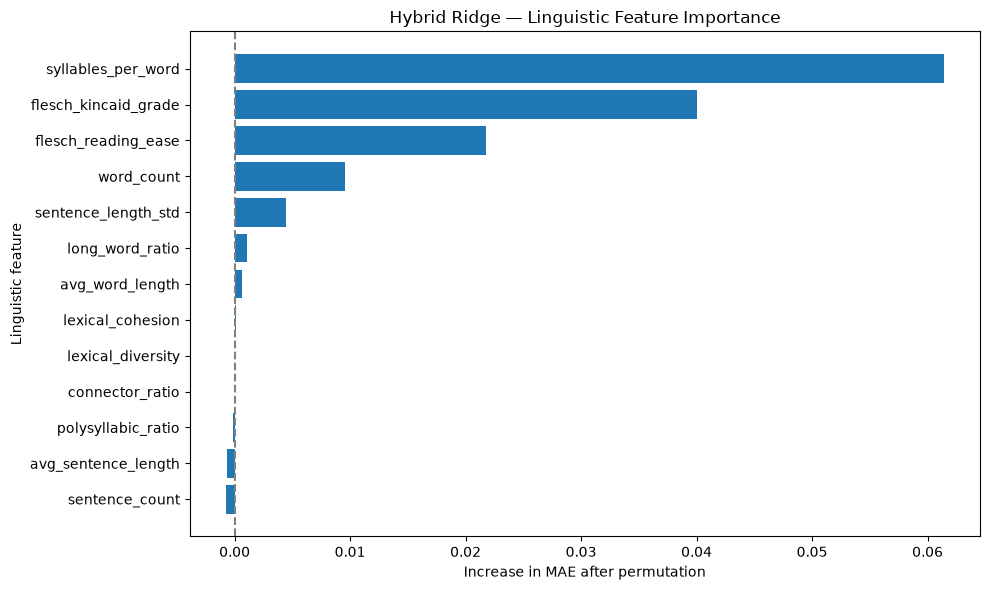

In [18]:

# 9.2 — Linguistic Feature Importance (Permutation)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import mean_absolute_error

assert best_representation == "Hybrid all (Ridge)", (
    "This cell is designed for the selected Hybrid Ridge model."
)

# 1. Original test performance
baseline_mae = mean_absolute_error(y[idx_test], test_pred)

print("Original Test MAE:", round(baseline_mae, 4))

# 2. Prepare the features once
X_words = final_word_vec.transform(test_texts)
X_chars = final_char_vec.transform(test_texts)

X_fixed = sparse.hstack(
    [X_words, X_chars],
    format="csr"
)

X_embeddings = sparse.csr_matrix(
    X_emb[idx_test].astype(np.float32)
)

X_linguistic = final_scaler.transform(
    X_manual.iloc[idx_test]
).astype(np.float32)

# Verify that the reconstructed input gives the original predictions
X_original = sparse.hstack(
    [
        X_fixed,
        sparse.csr_matrix(X_linguistic),
        X_embeddings
    ],
    format="csr"
)

assert np.allclose(
    final_model.predict(X_original), test_pred, atol=1e-4
)

# 3. Permute each linguistic feature
rng = np.random.default_rng(42)

results = []
n_repeats = 3

for j, feature_name in enumerate(FEATURE_NAMES):

    errors = []

    for repeat in range(n_repeats):

        # Copy the original linguistic features
        X_modified = X_linguistic.copy()

        # Shuffle only one feature
        X_modified[:, j] = rng.permutation(
            X_modified[:, j]
        )

        # Reconstruct the complete Hybrid input
        X_permuted = sparse.hstack(
            [
                X_fixed,
                sparse.csr_matrix(X_modified),
                X_embeddings
            ],
            format="csr"
        )

        # Predict using the existing model
        predictions = final_model.predict(X_permuted)

        # Calculate the new error
        mae = mean_absolute_error(
            y[idx_test],
            predictions
        )

        errors.append(mae)

    results.append({
        "Feature": feature_name,
        "MAE Increase": np.mean(errors) - baseline_mae,
        "Std": np.std(errors)
    })

# 4. Rank the features
importance_df = pd.DataFrame(results)

importance_df = importance_df.sort_values(
    "MAE Increase",
    ascending=False
)

display(importance_df.round(4))

# 5. Visualize feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["MAE Increase"]
)

plt.gca().invert_yaxis()

plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Increase in MAE after permutation")
plt.ylabel("Linguistic feature")
plt.title("Hybrid Ridge — Linguistic Feature Importance")

plt.tight_layout()
plt.show()


Original MAE: 0.5108


,Feature Group,MAE Increase,Std
3,MiniLM embeddings,0.2103,0.0166
2,Linguistic,0.1029,0.0110
1,Character TF-IDF,0.0622,0.0065
0,Word TF-IDF,0.0204,0.0065


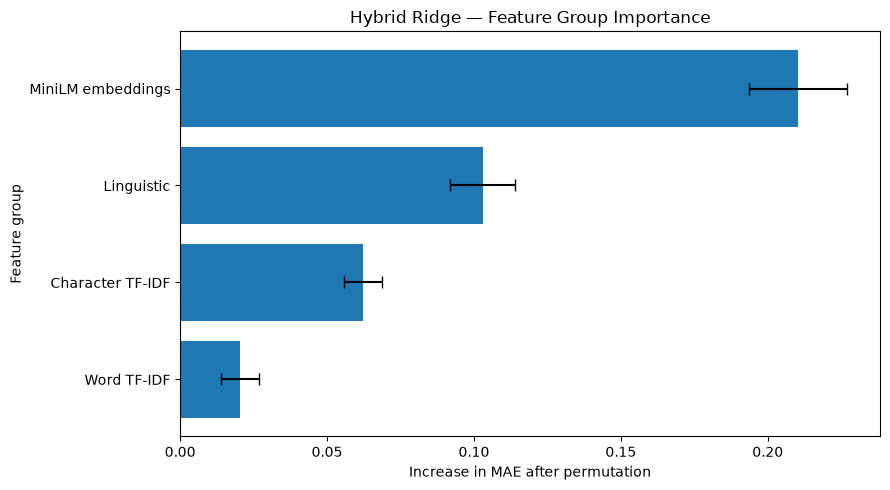

In [23]:
# 9.3 — Feature Group Importance (Permutation)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.metrics import mean_absolute_error

# Four feature groups
feature_groups = {
    "Word TF-IDF": X_words,
    "Character TF-IDF": X_chars,
    "Linguistic": sparse.csr_matrix(X_linguistic),
    "MiniLM embeddings": X_embeddings
}

# Original test matrix
X_original = sparse.hstack(
    list(feature_groups.values()),
    format="csr"
)

baseline_mae = mean_absolute_error(
    y[idx_test],
    final_model.predict(X_original)
)

print("Original MAE:", round(baseline_mae, 4))

rng = np.random.default_rng(42)
results_groups = []
n_repeats = 5

# Test each feature group
for group_name in feature_groups:

    errors = []

    for repeat in range(n_repeats):

        # Shuffle passage rows within one feature group
        permutation = rng.permutation(X_original.shape[0])

        modified_groups = []

        for name, matrix in feature_groups.items():

            if name == group_name:
                modified_groups.append(matrix[permutation])
            else:
                modified_groups.append(matrix)

        # Recombine all feature groups
        X_modified = sparse.hstack(
            modified_groups,
            format="csr"
        )

        # Predict with the same trained model
        predictions = final_model.predict(X_modified)

        # Calculate MAE
        mae = mean_absolute_error(
            y[idx_test],
            predictions
        )

        errors.append(mae)

    results_groups.append({
        "Feature Group": group_name,
        "MAE Increase": np.mean(errors) - baseline_mae,
        "Std": np.std(errors)
    })

# Results
group_importance_df = pd.DataFrame(results_groups)

group_importance_df = group_importance_df.sort_values(
    "MAE Increase",
    ascending=False
)

display(group_importance_df.round(4))

# Visualization
plt.figure(figsize=(9, 5))

plt.barh(
    group_importance_df["Feature Group"],
    group_importance_df["MAE Increase"],
    xerr=group_importance_df["Std"],
    capsize=4
)

plt.gca().invert_yaxis()
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Increase in MAE after permutation")
plt.ylabel("Feature group")
plt.title("Hybrid Ridge — Feature Group Importance")

plt.tight_layout()
plt.show()

## 10. Save full inference artifact

`low_cutoff` and `high_cutoff` are **development-set tertiles**. They produce relative categories: Difficult, Moderate, Easier. They are **not** official readability grade levels.

In [19]:
low_cutoff, high_cutoff = np.quantile(y[idx_dev], [1/3, 2/3])
artifact = {
    "model": final_model,
    "representation": best_representation,
    "alpha": best_alpha,
    "clear_median_words": int(X_manual.iloc[idx_dev]["word_count"].median()),
    "word_vectorizer": final_word_vec,
    "char_vectorizer": final_char_vec,
    "feature_scaler": final_scaler,
    "feature_names": FEATURE_NAMES,
    "encoder_name": EMBEDDING_MODEL,
    "low_cutoff": float(low_cutoff),
    "high_cutoff": float(high_cutoff),
    "validation_mae": float(selected["MAE"]),
    "test_mae": float(mean_absolute_error(y[idx_test], test_pred)),
    "target": "BT_easiness",
    "random_state": RANDOM_STATE,
}
MODEL_PATH = Path("readability_advanced_model.joblib")
joblib.dump(artifact, MODEL_PATH)
print("Saved:", MODEL_PATH.resolve())
print("Warning: load joblib artifacts only from trusted sources")

Saved: C:\Users\SetupGame\Desktop\nlp_proj_adv\src\nlp_proj_adv\readability_advanced_model.joblib


In [20]:
print(df["BT_easiness"].describe())

print("Lowest score:", df["BT_easiness"].min())
print("Highest score:", df["BT_easiness"].max())

count    4723.000000
mean       -0.957463
std         1.033696
min        -3.676268
25%        -1.696136
50%        -0.909047
75%        -0.203348
max         1.711390
Name: BT_easiness, dtype: float64
Lowest score: -3.676267773
Highest score: 1.711389827


## 11. Analyze a brand-new text (exactly like Streamlit)

No CLEAR row is needed here. The saved estimator uses numerical features and/or **its fitted TF-IDF vectorizers**. If the best representation needs embeddings, the pretrained encoder is used at prediction time.

Because the corpus contains mostly standard-length excerpts, results for very short passages are less reliable. The score is a prediction, not an established readability grade.

In [21]:
new_text = """
Technology has changed the way people learn and communicate. Many students now
use digital tools to find information and practice new skills. These tools can
make lessons more engaging, but they do not replace a good teacher. For example,
working in small groups helps students discuss ideas and ask questions. A good
learning environment combines helpful technology with clear explanations and
opportunities to practice. Therefore, schools should choose digital tools that
support their teaching goals rather than using technology for its own sake.
"""

saved_artifact = joblib.load(MODEL_PATH)
needs_encoder = (
    "Embeddings" in saved_artifact["representation"] or
    "Hybrid" in saved_artifact["representation"]
)
if needs_encoder and encoder is None:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer(EMBEDDING_MODEL)

prediction = predict_text(new_text, saved_artifact, encoder=encoder if needs_encoder else None)
print(f"Predicted BT_easiness: {prediction['score']:.3f} (higher = easier)")
print("Relative level:", prediction["level"])
print("Sentences:", int(prediction["features"]["sentence_count"]))
print("Word count:", int(prediction["features"]["word_count"]))
print("Suggestions:")
for suggestion in suggest_improvements(prediction["features"]):
    print(" -", suggestion)
display(pd.Series(prediction["features"], name="value").to_frame())

Batches: 100%|██████████| 1/1 [00:00<00:00,  6.48it/s]

Predicted BT_easiness: 0.077 (higher = easier)
Relative level: Easier (relative to CLEAR)
Sentences: 6
Word count: 83
Suggestions:
 - Review technical and long words; use clearer synonyms when accurate.


,value
word_count,83.000000
sentence_count,6.000000
avg_sentence_length,13.833333
sentence_length_std,2.967416
avg_word_length,5.518072
long_word_ratio,0.361446
polysyllabic_ratio,0.156627
syllables_per_word,1.662651
lexical_diversity,0.831325
connector_ratio,0.012048


## 12. Semantic continuity: sentence embeddings + cosine similarity

A low lexical overlap doesn't necessarily mean the ideas are incoherent: *pupils* and *students* can have related meanings without sharing the same word. A pretrained embedding can identify semantic similarity more flexibly.

We calculate cosine similarity **between each consecutive sentence**, then average. This provides a **semantic continuity proxy only**. Topic similarity is not a measure of logical contradiction, argument strength, causal validity, or true coherence. To make a validated *coherence* claim, we would need human-rated coherence labels and a separate test set.

Mean adjacent sentence cosine: 0.43
Lexical overlap: 0.02


,Sentence A,Sentence B,Cosine similarity
0,1,2,0.485
1,2,3,0.547
2,3,4,0.305
3,4,5,0.423
4,5,6,0.390


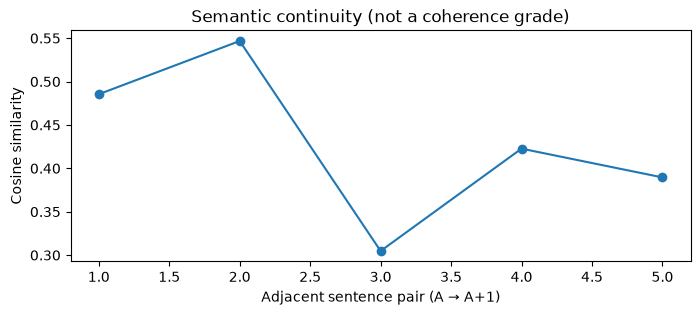

In [22]:
if encoder is None:
    print("Semantic analysis skipped: turn USE_EMBEDDINGS=True and rerun the embedding section.")
else:
    sem = semantic_cohesion(new_text, encoder)
    print("Mean adjacent sentence cosine:", None if sem["mean"] is None else round(sem["mean"], 3))
    print("Lexical overlap:", round(prediction["features"]["lexical_cohesion"], 3))
    if sem["pairs"]:
        continuity = pd.DataFrame({
            "Sentence A": range(1, len(sem["pairs"]) + 1),
            "Sentence B": range(2, len(sem["pairs"]) + 2),
            "Cosine similarity": sem["pairs"],
        })
        display(continuity.round(3))
        fig, ax = plt.subplots(figsize=(8, 3))
        ax.plot(continuity["Sentence A"], continuity["Cosine similarity"], marker="o")
        ax.set(xlabel="Adjacent sentence pair (A → A+1)", ylabel="Cosine similarity", title="Semantic continuity (not a coherence grade)")
        plt.show()

## 13. Reliability: external evaluation

1. **Repeat group splits** with several random seeds and report average ± standard deviation; a single split has uncertainty.
2. **Near-duplicate detection** across works; different source titles can still contain copied material.
3. **Grid search within development folds** for regularization, n-grams, and estimator choices. Never tune on the test set.
4. **Out-of-distribution tests:** very short passages, uncommon genres, non-English input, and texts with abbreviations.
5. **Human coherence labels:** if the goal is genuine discourse coherence, evaluate against a separate annotated dataset. Sentence cosine alone is insufficient.
6. **Human-in-the-loop feedback** for the generated suggestions; no rewrite should be assumed to preserve meaning.

### Deliverables

- Notebook: `Project20_Advanced_NLP.ipynb`
- Reusable utilities: `readability_advanced_utils.py`
- Trained artifact after execution: `readability_advanced_model.joblib`
- Web interface: `app_advanced.py` (run `uv run streamlit run app_advanced.py`)

### Citations / references
- CLEAR Corpus: https://github.com/scrosseye/CLEAR-Corpus
- SentenceTransformer model card: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
- scikit-learn TF-IDF: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html
- Your supplied NLP course: Chapter 2 (preprocessing), Chapter 3 (vectorization), Chapter 4 (modeling).

The following sections **do not retrain or change the CLEAR regression model**. They examine domain shift using OneStopEnglish as an **external evaluation benchmark only**, without training a separate OneStopEnglish classifier. External test articles are never used to select the inference mode.


## 17. Final notes: what we can and cannot claim

**We can report:** group-aware CLEAR cross-validation and held-out metrics; OneStopEnglish external triplet-ordering accuracy using a separate article-level holdout; and the share of external BT predictions outside the CLEAR development target range.

**We cannot claim:** OneStopEnglish `Elementary` automatically equals CLEAR `Easier`; averaging chunks produces a ground-truth human BT score; our cohesion proxy proves logical coherence; or a single random article split guarantees deployment accuracy. Additional independent corpora and human-rated readability labels are needed for stronger external validation.

**Model outputs:** the Streamlit app should show the CLEAR `BT_easiness` prediction, the CLEAR-relative category, and the lexical/semantic cohesion measurements. No OneStopEnglish level classifier is trained by this notebook. If you previously trained one, **delete or rename** `onestop_level_classifier.joblib` so the app does not load an old version.

**To launch the app:** `uv run streamlit run app_advanced.py` from the directory containing your saved `readability_advanced_model.joblib`.
